In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import verification_hooks as _verification_hooks
_verification_hooks.install_hooks()

**Logistic Regression + T0: no additional feature transformation**

This training involves the following steps: 
1. Load the shared splits
2. Build a sklearn pipeline
3. Train six regularization settings
4. Plot the validation curve
5. Select by validation F1
6. Inspect errors and save six comparable results rows

T0 is the **73-feature preprocessed baseline**. It still uses the shared category grouping, one-hot encoding, log1p and scaling. 
These are 6 of the project's minimum 72 model configurations. The official test set is neither loaded nor scored in this notebook.

**Logistic regression: probability, loss and regularization**
**Logistic regression** predicts the probability of an attack as $P(\text{attack}) = \sigma(w^\top x + b)$, where $\sigma(z) = 1 / (1 + e^{-z})$ squashes any number into (0, 1). It flags a flow as an attack when that probability is above 0.5, so the decision boundary $w^\top x + b = 0$ is a straight line (hyperplane) in the feature space it sees.

**Regularization:** sklearn minimizes

$$\frac{1}{2}\lVert w \rVert^2 + C \sum_{i} \text{log-loss}_i$$

`C` sets how much the model cares about fitting the training data compared to keeping the weights small.

**Smaller C means stronger regularization** and more weight shrinkage; **larger C means weaker regularization**. Changing C adjusts the fitted coefficients, not
the number of input features or the form of the T0 decision boundary.

**1. Setup and shared splits**

In [2]:
import sys
sys.path.append("..")  # allow imports from src/ when running in notebook/

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

from src.preprocessing import build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
RESULTS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, "validation:", X_val.shape)

train: (24000, 41) validation: (6000, 41)


**2. The pipeline**

T0 does not require any transformations, so we directly start with the pipeline.
The estimator uses sklearn's default L2 regularization
and `lbfgs` solver, with the same 2,000-iteration limit as T2.

Each call to `evaluate` fits a fresh pipeline on training only and scores validation
with those fitted parameters. For cross-validation, use this complete pipeline
with the raw training inputs.

In [3]:
def build(C):
    return make_pipeline(
        build_preprocessor(),
        LogisticRegression(C=C, max_iter=2000),
    )

**4. Regularization sweep: six values of C**

We decide to use C with 6 different values (C = 0.001, 0.01, 0.1, 1, 10, 100) to better compare the model's performance at different penalty parameters. **Smaller C means stronger regularization** and more weight shrinkage; **larger C means weaker regularization**.

These choices are planned comparisons, not claims that an unobserved model has already overfit. All six models use the same rows and default prediction threshold.

`f1_gap = train_f1 - val_f1`. A large positive gap can suggest overfitting. Similar scores on both splits require inspecting their absolute level and error patterns; they do not by themselves identify bias, noise or a lack of useful features.

In [4]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {}

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "LR", "T0", "C", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"C={value:g}: val F1={rows[-1]['val_f1']:.4f}, converged={rows[-1]['converged']}")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.drop(columns=["model", "transformation", "param"]).round(4)

C=0.001: val F1=0.9046, converged=True
C=0.01: val F1=0.9099, converged=True


C=0.1: val F1=0.9133, converged=True


C=1: val F1=0.9140, converged=True


C=10: val F1=0.9132, converged=True


C=100: val F1=0.9141, converged=True


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8474,0.9714,0.9051,0.1883,0.8501,0.9666,0.9046,0.1834,0.06,True,0.0005
1,0.010,0.8666,0.9592,0.9106,0.1589,0.8680,0.9559,0.9099,0.1564,0.05,True,0.0007
2,0.100,0.8742,0.9582,0.9143,0.1485,0.8776,0.9521,0.9133,0.1429,0.07,True,0.0009
3,1.000,0.8805,0.9537,0.9157,0.1393,0.8819,0.9486,0.9140,0.1367,0.12,True,0.0016
4,10.000,0.8839,0.9525,0.9169,0.1346,0.8841,0.9444,0.9132,0.1332,0.15,True,0.0037
5,100.000,0.8840,0.9542,0.9178,0.1347,0.8831,0.9473,0.9141,0.1349,0.20,True,0.0037


**5. Validation curve**

As in T2, the left plot compares training and validation F1, and the right plot
shows validation precision, recall and false positive rate. Attack is the positive
class. Check the results table's `converged` column; if any setting is False,
increase `max_iter` and rerun it before interpreting that setting.

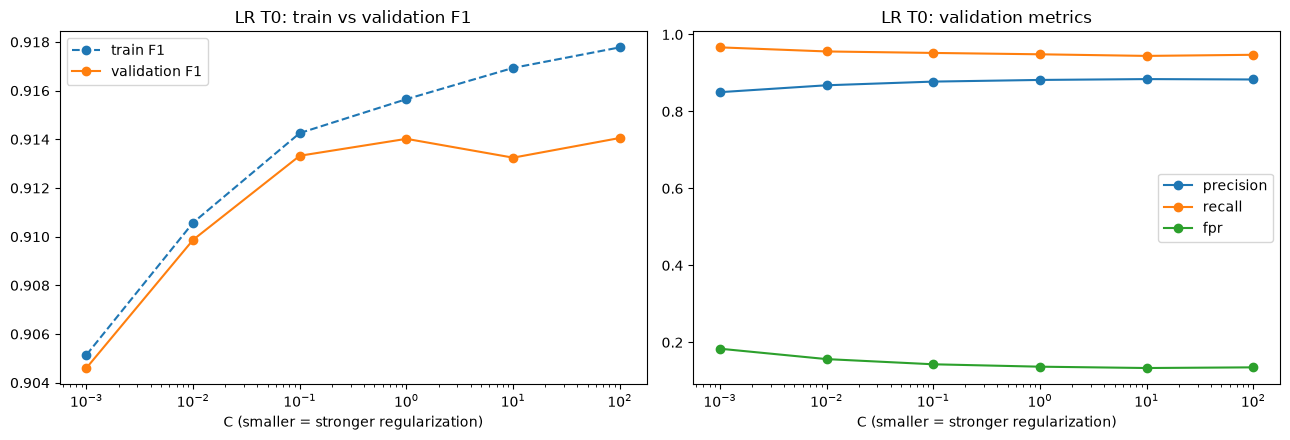

In [5]:
plot_sweep(results, "LR T0", FIGS / "curve_lr_t0.png")

**6. The best setting and validation errors**

Select the converged setting with the highest validation F1. Exact ties use the
first row in the ascending grid, favoring stronger regularization. An edge winner
suggests considering a wider grid; it does not guarantee a better score.
The selected validation score is not an untouched final test estimate.

In [6]:
converged = results[results["converged"]]
best = converged.loc[converged["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"Best C={best['value']:g}: val F1={best['val_f1']:.4f}, "
      f"precision={best['val_precision']:.4f}, recall={best['val_recall']:.4f}, "
      f"FPR={best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("Best C is at the grid edge: consider extending it.")

Best C=100: val F1=0.9141, precision=0.8831, recall=0.9473, FPR=0.1349
Best C is at the grid edge: consider extending it.


Rows of the confusion matrix are true labels and columns are predicted labels.
False positives are normal flows flagged as attacks; false negatives are missed
attacks. The shared evaluator reports

$$\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2TP}{2TP+FP+FN},\quad
\mathrm{FPR}=\frac{FP}{FP+TN}.$$

False positive rate is conditional on **normal** traffic, so the expected false
alarm count is FPR times the number of normal flows, not automatically all flows.

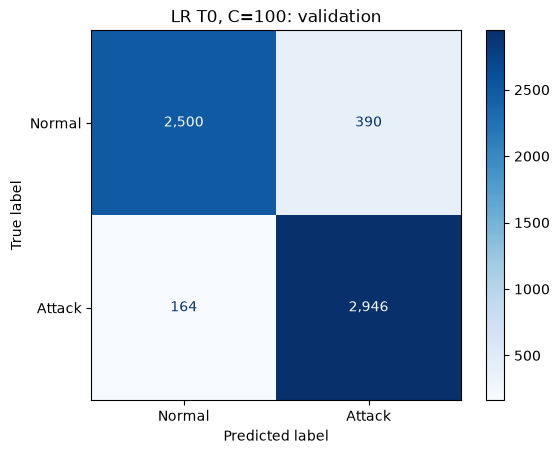

In [7]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",",
)
plt.title(f"LR T0, C={best['value']:g}: validation")
plt.savefig(FIGS / "confusion_lr_t0.png", dpi=150, bbox_inches="tight")
plt.show()

**Which attack types are missed?**

As in the reference notebook, inspect attack recall using `attack_cat` only as
metadata, never as a predictor. The EDA found feature-level overlap between
Fuzzers and Normal, so inspect Fuzzers explicitly rather than relying only on the
overall F1. Small validation groups such as Worms produce uncertain recall
estimates; catching every one of a few rows does not establish perfect detection.

In [8]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,770,129,0.857
Analysis,89,86,3,0.966
DoS,212,207,5,0.976
Exploits,1105,1085,20,0.982
Backdoor,85,84,1,0.988
Reconnaissance,419,414,5,0.988
Generic,233,232,1,0.996
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


**7. Save the results**

Save six rows to `results/lr_t0.csv` using the same columns and shared metrics as
T2, with `model="LR"`, `transformation="T0"` and `param="C"`. The comparison is
controlled: same splits, preprocessing, solver family, C grid, selection metric
and threshold; T0 retains 73 inputs while T2 uses its PCA representation. Do not
infer which is better before comparing the actual validation results.

The plots use T0-specific filenames, leaving T2 outputs intact. The official test
set remains reserved for the final selected configuration. Fitted pipelines stay
in memory in `fitted`; this notebook saves metrics, not a serialized model.

In [9]:
results.to_csv(RESULTS / "lr_t0.csv", index=False)
print("Saved", len(results), "rows to", RESULTS / "lr_t0.csv")

Saved 6 rows to /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/verification/t0_cleanup_2026-11-27/runs/lr_cleaned/workspace/results/lr_t0.csv


In [10]:
_verification_hooks.capture(globals())

VERIFIED 6 models; independent metrics and plot data agree. Best C=100.
